In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.ensemble import AdaBoostClassifier, GradientBoostingClassifier, RandomForestClassifier, ExtraTreesClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
import warnings
warnings.filterwarnings('ignore')

from google.colab import drive
drive.mount('/content/drive', force_remount=True)

# তোমার পাথ
path = '/content/drive/MyDrive/Thesis file/Feature_Extract_Formants/'

extractors = [
    'AlexNet', 'CustomCNN', 'DenseNet121', 'EfficientNetB0', 'InceptionV3',
    'MobileNetV2', 'ResNet50', 'VGG16', 'ViT', 'Xception'
]

classifiers = {
    'AdaBoost': AdaBoostClassifier(n_estimators=100, random_state=42),
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'Extra Trees': ExtraTreesClassifier(n_estimators=100, random_state=42),
    'Gradient Boosting': GradientBoostingClassifier(random_state=42),
    'KNN': KNeighborsClassifier(n_neighbors=5),
    'Logistic Regression': LogisticRegression(max_iter=2000, random_state=42),
    'Naive Bayes': GaussianNB(),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42),
    'SVM': SVC(random_state=42)
}

results = pd.DataFrame(columns=['Feature Extractor'] +
                       list(classifiers.keys()) + ['Best', 'Best Accuracy'])
results['Feature Extractor'] = extractors

print("\n🔰 Starting F1 + F2 + F3 merge processing...\n")

for extractor in extractors:
    print(f'\nProcessing {extractor} ...')

    # -------- FILES FOR F1 + F2 + F3 --------
    f1_file = f'{path}F1_Features_{extractor}.csv'
    f2_file = f'{path}F2_Features_{extractor}.csv'
    f3_file = f'{path}F3_Features_{extractor}.csv'

    df1 = pd.read_csv(f1_file)
    df2 = pd.read_csv(f2_file)
    df3 = pd.read_csv(f3_file)

    # -------- FIND LABEL COLUMN --------
    possible_label_cols = ['label', 'class', 'target', 'phoneme',
                           'category', 'Label', 'Class', 'phoneme_label']

    label_col = None
    for col in possible_label_cols:
        if col in df1.columns:
            label_col = col
            break

    if label_col is None:
        label_col = df1.columns[1]
        print(f"   → লেবেল কলাম ধরা হলো: {label_col}")

    # -------- CLEAN UNWANTED COLUMNS --------
    def clean_features(df):
        df = df.copy()
        drop_cols = [c for c in df.columns if any(x in c.lower()
                                                  for x in ['filename','path','unnamed','index'])]
        df.drop(columns=drop_cols, errors='ignore', inplace=True)
        return df

    df1_clean = clean_features(df1)
    df2_clean = clean_features(df2)
    df3_clean = clean_features(df3)

    # Separate features + label
    X1 = df1_clean.drop(columns=[label_col], errors='ignore')
    X2 = df2_clean.drop(columns=[label_col], errors='ignore')
    X3 = df3_clean.drop(columns=[label_col], errors='ignore')

    y = df1_clean[label_col]   # Take label from F1

    # ---------------- MERGE F1 + F2 + F3 ----------------
    X = pd.concat([
        X1.reset_index(drop=True),
        X2.reset_index(drop=True),
        X3.reset_index(drop=True)
    ], axis=1)

    # -------- SAFETY CHECK: Only 1 class --------
    if len(y.unique()) == 1:
        print(f"   ❌ Skipped {extractor}: Only 1 class → {y.unique()[0]}")
        for name in classifiers.keys():
            results.loc[results['Feature Extractor'] == extractor, name] = "NA"
        results.loc[results['Feature Extractor'] == extractor, 'Best'] = "NA"
        results.loc[results['Feature Extractor'] == extractor, 'Best Accuracy'] = "NA"
        continue

    # -------- TRAIN/TEST SPLIT --------
    try:
        X_train, X_test, y_train, y_test = train_test_split(
            X, y, test_size=0.2, random_state=42, stratify=y
        )
    except ValueError:
        print(f"   → Stratify সমস্যা: stratify ছাড়া split করা হলো")
        X_train, X_test, y_train, y_test = train_test_split(
            X, y, test_size=0.2, random_state=42
        )

    best_acc = 0
    best_name = ''

    # -------- RUN ALL CLASSIFIERS --------
    for name, clf in classifiers.items():
        clf.fit(X_train, y_train)
        y_pred = clf.predict(X_test)
        acc = round(accuracy_score(y_test, y_pred), 4)

        results.loc[results['Feature Extractor'] == extractor, name] = acc

        if acc > best_acc:
            best_acc = acc
            best_name = name

    results.loc[results['Feature Extractor'] == extractor, 'Best'] = best_name
    results.loc[results['Feature Extractor'] == extractor, 'Best Accuracy'] = best_acc

# -------- SAVE EXCEL --------
output_file = path + 'Summary_F1_F2_F3.xlsx'
results.to_excel(output_file, index=False)

print("\n✅ DONE! তোমার F1+F2+F3 Summary Excel তৈরি হয়েছে:")
print(output_file)
display(results)


Mounted at /content/drive

🔰 Starting F1 + F2 + F3 merge processing...


Processing AlexNet ...

Processing CustomCNN ...

Processing DenseNet121 ...

Processing EfficientNetB0 ...

Processing InceptionV3 ...

Processing MobileNetV2 ...

Processing ResNet50 ...

Processing VGG16 ...

Processing ViT ...

Processing Xception ...

✅ DONE! তোমার F1+F2+F3 Summary Excel তৈরি হয়েছে:
/content/drive/MyDrive/Thesis file/Feature_Extract_Formants/Summary_F1_F2_F3.xlsx


,Feature Extractor,AdaBoost,Decision Tree,Extra Trees,Gradient Boosting,KNN,Logistic Regression,Naive Bayes,Random Forest,SVM,Best,Best Accuracy
0,AlexNet,0.9143,0.781,0.9048,0.8952,0.9238,0.9429,0.7619,0.9048,0.9143,Logistic Regression,0.9429
1,CustomCNN,0.9238,0.7429,0.9238,0.9429,0.8952,0.9238,0.7048,0.9429,0.9524,SVM,0.9524
2,DenseNet121,0.8952,0.781,0.8952,0.8952,0.9143,0.9619,0.819,0.9048,0.8952,Logistic Regression,0.9619
3,EfficientNetB0,0.9333,0.8571,0.8667,0.9048,0.8095,0.9238,0.8571,0.8857,0.9048,AdaBoost,0.9333
4,InceptionV3,0.9143,0.7429,0.8667,0.8952,0.8762,0.9333,0.8571,0.8762,0.9143,Logistic Regression,0.9333
5,MobileNetV2,0.9333,0.819,0.8952,0.8857,0.9238,0.9524,0.8667,0.8952,0.9143,Logistic Regression,0.9524
6,ResNet50,0.9143,0.8571,0.8762,0.9524,0.8381,0.8857,0.8667,0.8952,0.9238,Gradient Boosting,0.9524
7,VGG16,0.9333,0.8095,0.9048,0.9143,0.8952,0.9429,0.7619,0.9048,0.9333,Logistic Regression,0.9429
8,ViT,0.8667,0.8381,0.8381,0.8571,0.8286,0.9048,0.819,0.8286,0.8476,Logistic Regression,0.9048
9,Xception,0.9333,0.8667,0.8476,0.8952,0.7619,0.9619,0.8381,0.8476,0.8667,Logistic Regression,0.9619


Mounted at /content/drive

🎯 Best Feature Extractor: DenseNet121
🎯 Best Classifier: Logistic Regression (Accuracy: 0.9619)



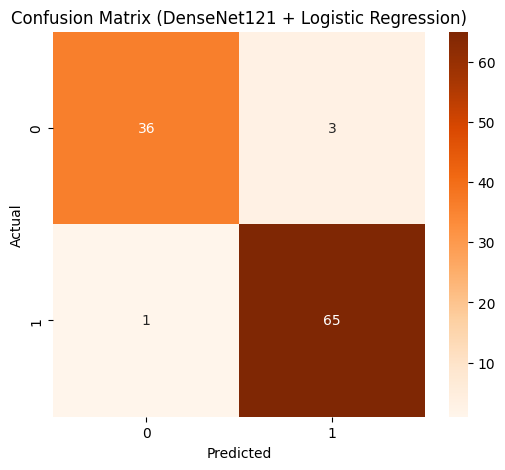


📊 Performance Summary Table:



,Metric,Value (%)
0,Accuracy,96.19
1,Precision,96.44
2,Recall,95.40
3,F1-Score,95.88


In [6]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score
from sklearn.ensemble import AdaBoostClassifier, GradientBoostingClassifier, RandomForestClassifier, ExtraTreesClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

from google.colab import drive
drive.mount('/content/drive', force_remount=True)

# ==============================
# Paths
# ==============================
path_features = '/content/drive/MyDrive/Thesis file/Feature_Extract_Formants/'
results_path = path_features + 'Feature_Extract/'  # এখানে আগে feature_path লিখেছিলে
results_file = results_path + 'F1+F2+F3.xlsx'

# ==============================
# Load results
# ==============================
results = pd.read_excel(results_file)

# Find the best accuracy row
best_row = results.loc[results['Best Accuracy'].idxmax()]
best_extractor = best_row['Feature Extractor']
best_classifier_name = best_row['Best']

print(f"\n🎯 Best Feature Extractor: {best_extractor}")
print(f"🎯 Best Classifier: {best_classifier_name} (Accuracy: {best_row['Best Accuracy']})\n")

# ==============================
# Load F1+F2+F3 features for that extractor
# ==============================
f1_file = f'{path_features}F1_Features_{best_extractor}.csv'
f2_file = f'{path_features}F2_Features_{best_extractor}.csv'
f3_file = f'{path_features}F3_Features_{best_extractor}.csv'

df1 = pd.read_csv(f1_file)
df2 = pd.read_csv(f2_file)
df3 = pd.read_csv(f3_file)

# Detect label column
possible_label_cols = ['label', 'class', 'target', 'phoneme', 'category', 'Label', 'Class', 'phoneme_label']
label_col = None
for col in possible_label_cols:
    if col in df1.columns:
        label_col = col
        break
if label_col is None:
    label_col = df1.columns[1]

y = df1[label_col]

# Clean features
def clean_features(df):
    df = df.copy()
    drop_cols = [c for c in df.columns if any(x in c.lower() for x in ['filename','path','unnamed','index'])]
    df.drop(columns=drop_cols, errors='ignore', inplace=True)
    return df

X1 = clean_features(df1).drop(columns=[label_col], errors='ignore')
X2 = clean_features(df2).drop(columns=[label_col], errors='ignore')
X3 = clean_features(df3).drop(columns=[label_col], errors='ignore')

X = pd.concat([X1.reset_index(drop=True),
               X2.reset_index(drop=True),
               X3.reset_index(drop=True)], axis=1)

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

# Classifier dictionary
classifiers = {
    'AdaBoost': AdaBoostClassifier(n_estimators=100, random_state=42),
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'Extra Trees': ExtraTreesClassifier(n_estimators=100, random_state=42),
    'Gradient Boosting': GradientBoostingClassifier(random_state=42),
    'KNN': KNeighborsClassifier(n_neighbors=5),
    'Logistic Regression': LogisticRegression(max_iter=2000, random_state=42),
    'Naive Bayes': GaussianNB(),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42),
    'SVM': SVC(random_state=42)
}

# Instantiate best classifier
clf = classifiers[best_classifier_name]
clf.fit(X_train, y_train)
y_pred = clf.predict(X_test)

# ==============================
# Confusion Matrix
# ==============================
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Oranges', xticklabels=np.unique(y), yticklabels=np.unique(y))
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title(f'Confusion Matrix ({best_extractor} + {best_classifier_name})')
plt.show()

# ==============================
# Performance Table
# ==============================
accuracy = round(100*accuracy_score(y_test, y_pred), 2)
precision = round(100*precision_score(y_test, y_pred, average='macro'), 2)
recall = round(100*recall_score(y_test, y_pred, average='macro'), 2)
f1 = round(100*f1_score(y_test, y_pred, average='macro'), 2)

performance_summary = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1-Score'],
    'Value (%)': [accuracy, precision, recall, f1]
})

print("\n📊 Performance Summary Table:\n")
display(performance_summary)
